In [134]:
import random
import time
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import colormaps as cm

# Oppgave 1

### Oppgave 1a)

For å lage en monomer har vi tatt utgangspunkt i en N*N-matrise med nummererte monomerer fra 1 til N. Dette er hovedsakelig for å enkelt illustrere polymeren.
For å minimere antall iterasjoner når polymeren skal manipuleres, og dermed kjøretiden til programmet, har vi brukt np.argwhere()-funksjonen. Funksjonen returnerer et to-dimasjonalt array med posisjonen til alle ikke-null elementer i matrisen. Samlingen av koordinater kan dermed anses som vektorer, som er enklere å jobbe med for både oss og kompilatoren. 

### Oppgave 1b)

In [135]:
def create_initial_polymer(N):
    grid = np.zeros((N, N), dtype=int)          # to-dimansjonalt grid uten polymer
    grid[int(N / 2)] = np.arange(1, N + 1)      # legger inn horisontalt polymer
    return grid

### oppgave 1c)

Dersom vi forsøker å rotere om endepunktene vil den ikke rotere. Det er derfor ikke nødvendig å inkludere disse i løkkene.

### oppgave 1d)

In [185]:

# ----------------- Plotting -----------------
def plot2(polymer,N, fig, ax, name):

    # now later you get a new subplot; change the geometry of the existing
    polymer = polymer[~np.all(polymer == 0, axis=1)]
    polymer = polymer[:, ~np.all(polymer == 0, axis=0)]
    nx, ny = np.shape(polymer)
    polymer = np.ma.masked_where(polymer == 0, polymer)
    cmap = cm.get_cmap("plasma").copy()
    cmap.set_bad(color="white")
    
    n = len(fig.axes)

    # add the new
    ax = fig.add_subplot(n+1, 1, n+1)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(name)
    ax.grid(True, linewidth=0.2)
    for i in range(nx):
        for j in range(ny):
            c = polymer[i, j]
            if c != 0:
                ax.text(
                    j + 0.5,
                    i + 0.5,
                    str(int(c)),
                    va="center",
                    ha="center",
                    fontsize=8,
                    color="white",
                )

    im = ax.pcolormesh(
        polymer,
        cmap=cmap,
        linewidth=0.5,
        antialiased=True,
    )
    cbar = fig.colorbar(
        im,
        ticks=np.arange(1, N + 1, np.floor(N / 10)),
        boundaries=np.arange(1, N + 1, 1),
    )
    cbar.set_label("monomer")
    plt.show()




def plot(polymer, N, name):


    polymer = polymer[~np.all(polymer == 0, axis=1)]
    polymer = polymer[:, ~np.all(polymer == 0, axis=0)]
    nx, ny = np.shape(polymer)
    polymer = np.ma.masked_where(polymer == 0, polymer)
    cmap = cm.get_cmap("plasma").copy()
    cmap.set_bad(color="white")

    


    fig, ax = plt.subplots(figsize=(5, 5))
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(name)
    ax.grid(True, linewidth=0.2)
    for i in range(nx):
        for j in range(ny):
            c = polymer[i, j]
            if c != 0:
                ax.text(
                    j + 0.5,
                    i + 0.5,
                    str(int(c)),
                    va="center",
                    ha="center",
                    fontsize=8,
                    color="white",
                )
    

    
    im = ax.pcolormesh(
        polymer,
        cmap=cmap,
        linewidth=0.5,
        antialiased=True,
    )
    cbar = fig.colorbar(
        im,
        ticks=np.arange(1, N + 1, np.floor(N / 10)),
        boundaries=np.arange(1, N + 1, 1),
    )
    cbar.set_label("monomer")
    plt.tight_layout()
    plt.show()

### Oppgave 1e)

In [137]:
def surroundings(polymer, monomer):

    y, x = monomer
    max_y, max_x = polymer.shape
    surrounding_values = []

    if y > 0:
        surrounding_values.append(polymer[y - 1, x])  # Up
    if y < max_y - 1:
        surrounding_values.append(polymer[y + 1, x])  # Down
    if x > 0:
        surrounding_values.append(polymer[y, x - 1])  # Left
    if x < max_x - 1:
        surrounding_values.append(polymer[y, x + 1])  # Right
    return surrounding_values


def is_intact(polymer, N):
    vectors = np.argwhere(polymer > 0)

    for monomer in vectors:
        surroundings_arr = surroundings(polymer, monomer)
        y, x = monomer[0], monomer[1]
        val = polymer[y, x]
        vals = []
        vals.append(val)

        if len(set(vals)) != len(vals):
            return False

        if val == 1:
            elements = [2]
        elif val == N:
            elements = [N - 1]
        else:
            elements = [val - 1, val + 1]

        if not all(elem in surroundings_arr for elem in elements):  # sjekker naboer
            return False

    if len(vectors) != N:  # checking amount of numbers
        return False

    return True


### Oppgave 1f)

In [138]:

def rotate(polymer, coord, direction):
    rotated_polymer = np.copy(polymer)
    N = len(rotated_polymer)

    i, j = coord[0], coord[1]

    # definerer om rotasjonen skal skje for verdiene over eller under mrot.
    lower_vals = False

    mrot = rotated_polymer[i, j]

    if mrot <= int(
        N / 2
    ):  # for mrot i midten vil den rotere monomerer med lavere nummer.
        lower_vals = True

    if lower_vals:  # lokaliserer monomerer som skal roteres
        vectors = np.argwhere(np.logical_and(rotated_polymer > 0, polymer < mrot))
    else:
        vectors = np.argwhere(rotated_polymer > mrot)

    if (
        direction
    ):  # lager rotasjonsmatrise, bytter om på x- og y-akse for å passe iterering gjennom 2D-array
        rot_matrix = np.matrix("0, -1; 1, 0")
    else:
        rot_matrix = np.matrix("0, 1; -1, 0")

    for vector in vectors:
        i, j = vector[0], vector[1]

        val = rotated_polymer[i, j]
        rotated_polymer[i, j] = 0
        rel_coord = vector - coord
        rot_rel_coord = np.dot(rot_matrix, rel_coord)
        new_coord = rot_rel_coord + coord
        new_i, new_j = new_coord[0, 0], new_coord[0, 1]
        rotated_polymer[new_i, new_j] = val

    return polymer, rotated_polymer

### oppgave 1g)

Utfører en Monte Carlo-simulering av polymerfolding ved å rotere polymeren.

Parametere:
N (int):        Antall monomerer i polymeren.
Ns (int):       Antall Monte Carlo-steg som skal utføres.

Returnerer:
tuple:          En tuple bestående av den resulterende polymeren, antall vellykkede rotasjoner og total tid brukt.

In [139]:
def rotate_test(N, Nf, intact_func=is_intact):

    start = time.time()
    c = 1
    temp_polymer = create_initial_polymer(N)

    for i in range(1, Nf):
        monomer = np.argwhere(temp_polymer > 0)
        coord = monomer[np.random.randint(0, N)]
        rot = random.randint(0, 1)
        start_rot = time.time()
        old_polymer, rot_polymer = rotate(temp_polymer,coord,rot)
        stop_rot = time.time()
        if intact_func(rot_polymer, N):
            c += 1
            temp_polymer = rot_polymer
        else:
            temp_polymer = old_polymer
            
    slutt = time.time()
    total_time = slutt-start
    rot_time = stop_rot-start_rot
    return temp_polymer, c, rot_time, total_time

In [152]:
polymer_15_4,_ , _, _ = rotate_test(15, 4) 
polymer_15_1000, _, rot_time, t_is_intact = rotate_test(15, 1000)

#np.save("polymer_15_4", polymer_15_4)

1h) 

Brukte først følgende kode for å sjekke om polymeren var intakt:

In [141]:
def intactPolymer(polymer, N):
    counter = 0
    pol_arr = []
    length = False
    val = False
    pol_len = len(polymer)
    neighbour_1 = False
    neighbour_2 = False
    neighbour_3 = False
    try:
        for i in range(pol_len):
            for j in range(pol_len):
                if polymer[i,j] != 0:
                    counter += 1
                    
                    pol_arr.append(polymer[i,j])

                    if polymer[i,j] == 1:
                        if (polymer[i - 1,j] == 2 or polymer[i + 1,j] == 2 or 
                        polymer[i,j - 1] == 2 or polymer[i,j + 1] == 2):
                            neighbour_1 = True

                    elif polymer[i,j] == N:
                            if (polymer[i - 1,j] == N-1 or polymer[i + 1,j] == N-1 or 
                            polymer[i,j - 1] == N-1 or polymer[i,j + 1] == N-1):
                                neighbour_2 = True
                    
                    else:
                        if (polymer[i,j] == 1 + polymer[i - 1,j] or polymer[i,j] == 1 + polymer[i + 1,j] or 
                        polymer[i,j] == 1 + polymer[i,j - 1] or polymer[i,j] == 1 + polymer[i,j + 1]) and (polymer[i,j] == -1 + polymer[i - 1,j] or polymer[i,j] == -1 + polymer[i + 1,j] or 
                        polymer[i,j] == -1 + polymer[i,j - 1] or polymer[i,j] == -1 + polymer[i,j + 1]):
                            neighbour_3 = True
                
        if counter == N:
            length = True

        
        delete_arr = set(pol_arr)
        if len(delete_arr) == len(pol_arr):
            val = True
                

        if (length and val and neighbour_1 and neighbour_2 and neighbour_3):
            return True
            
        else:
            return False 
            
            
        
    except IndexError:
        return False

In [142]:
_, _, rot_time1, t_is_intact = rotate_test(100, 1000)
_, _, rot_time2, t_intactPolymer = rotate_test(100, 1000, intact_func=intactPolymer)
print(rot_time1)
print(rot_time2)
print(t_intactPolymer)
print(t_is_intact)

0.0005438327789306641
0.0005009174346923828
3.870655059814453
1.6620450019836426


For en polymer med N = 15 og Ns = 1000 vil intactPolymer() bruke {{ t_intactPolymer }} sekunder.
Med koden vi har implementert, is_intact(), vil samme polymer ferdigstilles på {{t_is_intact}} sekunder.

Oppgave i)

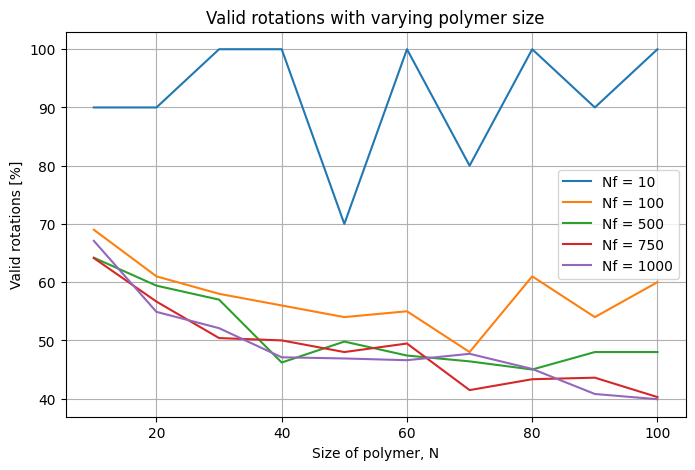

In [143]:
def test_valid_rotations():
    N = np.arange(10, 101, 10)
    p_Nf1 = []
    p_Nf2 = []
    p_Nf3 = []
    p_Nf4 = []
    p_Nf5 = []

    Nf1 = 10
    Nf2 = 100
    Nf3 = 500
    Nf4 = 750
    Nf5 = 1000

    fig, ax = plt.subplots(figsize=(8, 5))
    for i in N:
        _, c1, _, _ = rotate_test(i, Nf1)
        _, c2, _, _ = rotate_test(i, Nf2)
        _, c3, _, _ = rotate_test(i, Nf3)
        _, c4, _, _ = rotate_test(i, Nf4)
        _, c5, _, _ = rotate_test(i, Nf5)

        p_Nf1.append((c1/Nf1)*100)
        p_Nf2.append((c2/Nf2)*100)
        p_Nf3.append((c3/Nf3)*100)
        p_Nf4.append((c4/Nf4)*100)
        p_Nf5.append((c5/Nf5)*100)

    ax.plot(N, p_Nf1, label = (f'Nf = {Nf1}'))
    ax.plot(N, p_Nf2, label = (f'Nf = {Nf2}'))
    ax.plot(N, p_Nf3, label = (f'Nf = {Nf3}'))
    ax.plot(N, p_Nf4, label = (f'Nf = {Nf4}'))
    ax.plot(N, p_Nf5, label = (f'Nf = {Nf5}'))
    ax.grid()
    ax.legend()
    ax.set_xlabel('Size of polymer, N')
    ax.set_ylabel('Valid rotations [%]')
    ax.set_title('Valid rotations with varying polymer size')
    plt.show()


test_valid_rotations()

Ved flere forsøkte rotasjoner har prosentandelen gyldige rotasjoner en nedadgående trend når polymerlengden N øker. For liten Ns er det såpass få rotasjoner som skal gjennomføres at det faktisk er en markant sannsynlighet for å unngå kollisjoner i det hele tatt. Nf = 10 viser dette, hvor det er vilkårlig om feilkveiling oppstår eller ikke. Kontrasten i prosent-variasjon i grafene skyldes vektingen av hver rotasjon: En ugyldig rotasjon vil senke prosentandelen p = (rotasjon)/(Nf) mye mer når Nf er mindre.

Når polymeren er stor er det større sannsynlighet for at rotasjonen forårsaker kollisjon mellom monomerer. Endene blir lange, antall monomerer som kan roteres om øker, og alle rotasjonsmulighetene gjør at polymeren kan låse seg fast i ugunstige konfigurasjoner. 
Antall mulige rotasjoner går altså opp i takt med N, samtidig som gyldige rotasjoner minker. p = (rotasjon)/(Nf) blir derfor mindre.
Dette gjenspeiles også i grafen, som synker med økende N for Nf større enn omtrent 100.

Oppgave 1j:

In [144]:
def matrixV(N,a=-1):
    # N: Størrelse på V
    # k: konstant som fyller V
    return np.array([[a if (j < i - 1) or (j > i + 1) else 0 for j in range(N)] for i in range(N)])

In [145]:
def polymer_energy(polymer, vMatrix):
    vectors = np.argwhere(polymer > 0)
    N = len(polymer)
    E = 0
    for monomer in vectors:
        surroundings_arr = surroundings(polymer, monomer)
        y, x = monomer[0], monomer[1]
        val = polymer[y, x]
        for i in range(N):
            m = val
            n = i + 1
            if n in surroundings_arr:
                E += 1 / 2 * vMatrix[m - 1, i]
    return E

Vi har i koden over kuttet ut å definere en b som blir 0 eller 1 avhengig av om monomeren er nabo eller ikke, og heller bare gjort uttregningen med en gang. Dette for å unngå unødvendige variabler og utregninger.

Energi i polymer med N = 15 og 4 rotasjoner: 0.0
Energi i polymer med N = 15 og 1000 rotasjoner: -3.0


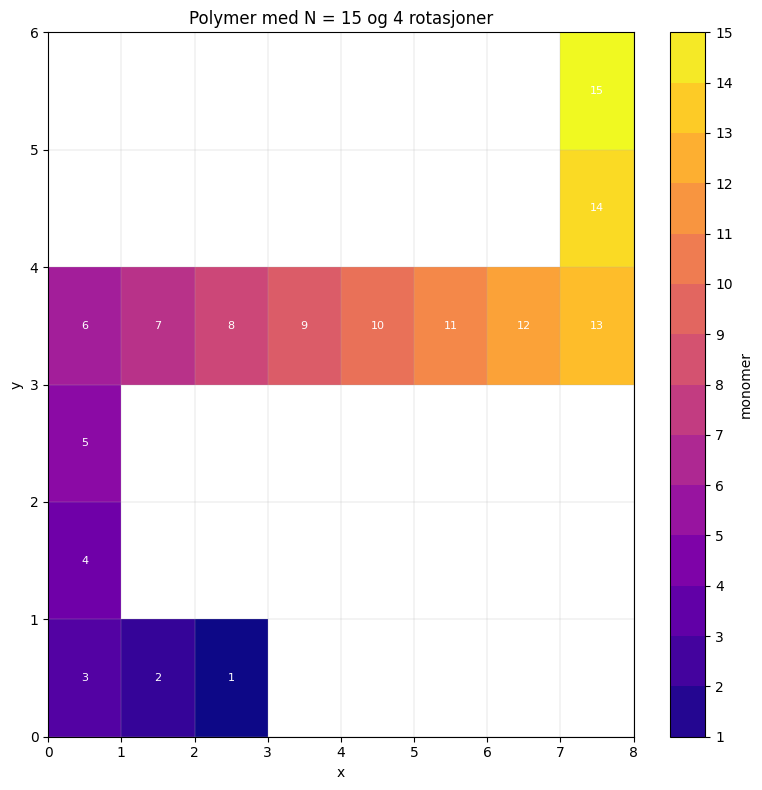

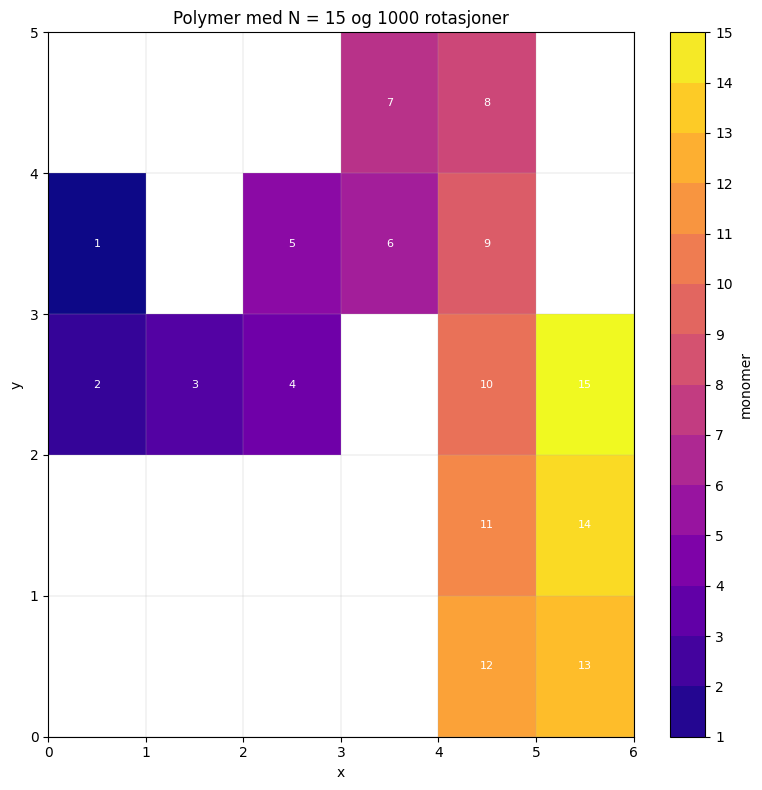

In [186]:
E_15_4 = polymer_energy(polymer_15_4, matrixV(15))
E_15_1000 = polymer_energy(polymer_15_1000, matrixV(15))

print(f'Energi i polymer med N = 15 og 4 rotasjoner: {E_15_4}')
print(f'Energi i polymer med N = 15 og 1000 rotasjoner: {E_15_1000}')

plot(polymer_15_4, 15, 'Polymer med N = 15 og 4 rotasjoner')
plot(polymer_15_1000, 15, 'Polymer med N = 15 og 1000 rotasjoner')

At polymeren som har forsøkt å rotere 1000 ganger har lavest energi er som forventet. Jo flere rotasjoner, jo mer sammenkveilet blir polymeret. Å havne i en konfigurasjon som minker energien krever mange rotasjonsforsøk ettersom polymeren ofte kolliderer inn i seg selv når monomerer uten kovalent binding havner såpass tett. Ved 1000 forsøk vil polymeren ha flere muligheter til å skape vellykkede rotasjonsforsøk som skaper svake vekselvirkninger, og derfor miker energien.

# Oppgave 2

Metropolisalgoritme:

In [158]:
def metropolis(polymer, V, Ns, T):
    """
    Utfører Metropolis Monte Carlo-simulering for polymerfolding.

    Args:
        polymer (numpy.ndarray): En array som representerer polymeren.
        V (numpy.ndarray): En array som representerer potensialet.
        Ns (int): Antall Monte Carlo-steg som skal utføres.
        T (float): Temperaturen i systemet.
        beta (float, optional): Invers temperatur. Standardverdi er 1.

    Returns:
        numpy.ndarray: En array med energiverdiene for hvert Monte Carlo-steg.
    """
    k_boltsmann = 1.38e-23
    beta=1/(k_boltsmann * T)
    N = len(polymer)
    E_array = np.zeros(Ns+1)
    E = polymer_energy(polymer, V)
    i = 0
    while i < Ns:
        monomer = np.argwhere(polymer > 0)
        coord = monomer[np.random.randint(0, N)]
        dir = random.randint(0, 1)
        polymer, rot_polymer = rotate(polymer, coord, dir)
        if is_intact(rot_polymer, N):
            i += 1
            E_new = polymer_energy(rot_polymer, V)

            if E_new < E:
                polymer = rot_polymer
                E = E_new
            elif np.random.random() < np.exp(-beta * (E_new - E)):
                polymer = rot_polymer
                E = E_new
            E_array[i] = E
    return polymer, E_array

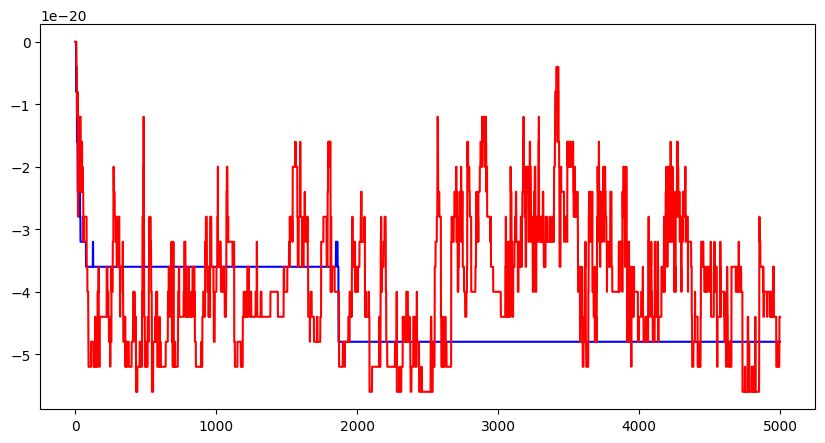

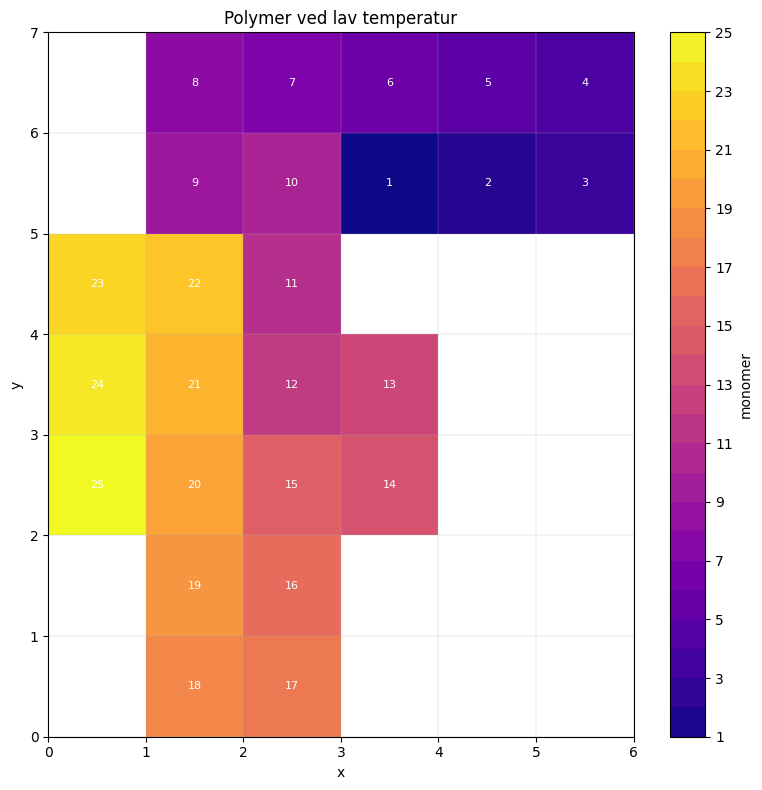

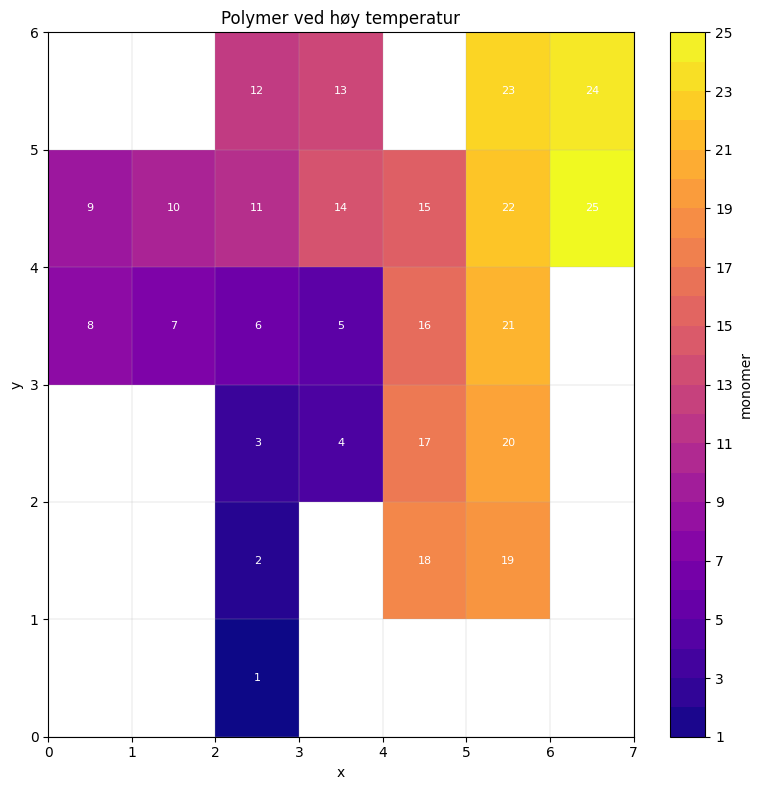

In [187]:
def test_metropolis(c = 1):

    # Konstanter
    N, Ns = 25, 5000
    polymer = create_initial_polymer(N)
    k = 4e-21 # enhet: [J/K]
    V = k*matrixV(N)

    # Simulering 1
    T_lav = 50 # 50 K < T_lav < 100K
    polymer_1, E_1 = metropolis(polymer, V, Ns, T_lav)

    # Simulering 2
    T_hoy = 300 # [K] - 293 K < T_hoy < 373 K
    polymer_2, E_2 = metropolis(polymer, V, Ns, T_hoy)

    fig, ax = plt.subplots(1, 1,figsize = (10, 5))
    # Plott
    ax.plot(E_1, 'b', label=f'E1, (T_lav = {T_lav})')
    ax.plot(E_2, 'r', label=f'E2 (T_hoy = {T_hoy})')
    #plt.xlabel('t')
    #plt.ylabel('E [J]')
    #plt.legend()
    #plt.grid()
    #plt.show()

    plot(polymer_1, N, 'Polymer ved lav temperatur')
    plot(polymer_2, N, 'Polymer ved høy temperatur')
test_metropolis()

Ser tydelig forskjell mellom de to grafene. En fellesnevner er at begge polymerer vil strebe etter å minimere egen energi, som kommer tydeligst
frem i polymeren med lav energi.
Fysisk sett er sannsynligheten for tilfeldige, ugunstige rotasjoner større ved høyere temperatur.
I koden simuleres dette stokastisk. Ved høy temperatur vil beta = 1/(k_b*T) bli liten, som igjen fører til at exp(-beta*delta_E) blir stor/nærmere 1, relativt til ved lav temperatur.
Når eksponensialleddet er nærmere 1 vil den tilfeldige p-en vår mest sannsynlig være mindre, og en rotering mot høyere energinivå kan forekomme. 

Grafen for polymeren i høy temperatur viser den høyfrekvente fluktueringen, men også polymerens tendens til å rotere mot lavere energi.
Grafen har plutselige hopp, som raskt synker ved at polymeren roteres mot lavere energitilstand.
Polymeren ved lavere energi kan også oppleve ugunstige rotasjoner, men dette oppstår kun et fåtall av ganger. Garfen viser at energien
stabiliserer seg ved en viss verdi, et minimum. Dette skjer når det ikke finnes flere monomerer den kan rotere rundt som minimerer energien.
Den eksakte verdien kommer til å variere avhengig av hvordan polymeren kveiler seg, ettersom den kan "låse seg fast" i både energirike og energifattige konfigurasjoner.
Ved høy temperatur vil ikke verdien stabilisere seg på samme måte, men bunnpunktene av grafen går igjen, som tyder på at dette er minimumsenergien
dersom de tilfeldige fluktueringene ikke hadde oppstått.